# Lab 12 — Código y mediciones (Partes 1 y 2)

CC3069 · Integrante A. Las predicciones y el marco teórico están en `investigacion.md` (escrito antes de correr). Aquí se compila, se corren los modos `amdahl` y `suma`, se generan las gráficas y se calculan S, E, C y F.

Todos los CSV y PNG quedan en `resultados/`.

In [1]:
import os, subprocess, shlex
import pandas as pd
from IPython.display import Image, display, Markdown

RAIZ = os.path.abspath('.')
RES = os.path.join(RAIZ, 'resultados')
os.makedirs(RES, exist_ok=True)

def sh(cmd, cwd=RAIZ, salida=None):
    """Corre un comando, muestra '$ cmd' y su salida (sirve de evidencia)."""
    print(f'$ {cmd}' + (f' > {salida}' if salida else ''))
    r = subprocess.run(cmd, shell=True, cwd=cwd, capture_output=True, text=True)
    if salida:
        with open(os.path.join(cwd, salida), 'w') as f:
            f.write(r.stdout)
    print(r.stdout, end='')
    if r.stderr:
        print(r.stderr, end='')
    r.check_returncode()
    return r.stdout

## Datos del equipo

In [2]:
sh('sysctl -n machdep.cpu.brand_string hw.physicalcpu hw.logicalcpu')
sh('sysctl hw.perflevel0.name hw.perflevel0.physicalcpu hw.perflevel0.l2cachesize '
   'hw.perflevel1.name hw.perflevel1.physicalcpu hw.perflevel1.l2cachesize '
   'hw.l1dcachesize hw.memsize')
sh('pmset -g batt | head -1')

$ sysctl -n machdep.cpu.brand_string hw.physicalcpu hw.logicalcpu
Apple M5 Pro
15
15
$ sysctl hw.perflevel0.name hw.perflevel0.physicalcpu hw.perflevel0.l2cachesize hw.perflevel1.name hw.perflevel1.physicalcpu hw.perflevel1.l2cachesize hw.l1dcachesize hw.memsize
hw.perflevel0.name: Super
hw.perflevel0.physicalcpu: 5
hw.perflevel0.l2cachesize: 16777216
hw.perflevel1.name: Performance
hw.perflevel1.physicalcpu: 10
hw.perflevel1.l2cachesize: 8388608
hw.l1dcachesize: 65536
hw.memsize: 25769803776
$ pmset -g batt | head -1
Now drawing from 'Battery Power'


"Now drawing from 'Battery Power'\n"

## Compilación

In [3]:
sh('make clean && make')
sh('./lab12 || true')  # sin argumentos muestra el uso

$ make clean && make
rm -f lab12 *.png *_con_S_E.csv
clang -O2 -Wall -Xpreprocessor -fopenmp -I/opt/homebrew/opt/libomp/include -o lab12 lab12_speedup.c -L/opt/homebrew/opt/libomp/lib -lomp
$ ./lab12 || true


Uso:
  ./lab12 amdahl     [W=400000] [fp=0.90] [pmax=15]
  ./lab12 suma       [pmax=15]
  ./lab12 desbalance [static|dynamic|guided] [W=40000] [pmax=15]
  ./lab12 gustafson  [W_por_hilo=100000] [W_seq=20000] [pmax=15]


''

## Parte 1 — Amdahl (W = 400 000, p = 1…15)

In [4]:
FPS = {'100': '1.00', '95': '0.95', '90': '0.90', '75': '0.75', '50': '0.50'}
for k, fp in FPS.items():
    sh(f'../lab12 amdahl 400000 {fp}', cwd=RES, salida=f'amdahl_fp{k}.csv')
    print()

$ ../lab12 amdahl 400000 1.00 > amdahl_fp100.csv


modo,N,p,param,t_seq,t_par,t_parte_seq
amdahl,400000,1,fp=1.00,0.302829,0.301577,0.000000
amdahl,400000,2,fp=1.00,0.302829,0.153388,0.000000
amdahl,400000,3,fp=1.00,0.302829,0.102832,0.000000
amdahl,400000,4,fp=1.00,0.302829,0.076062,0.000000
amdahl,400000,5,fp=1.00,0.302829,0.060291,0.000000
amdahl,400000,6,fp=1.00,0.302829,0.050003,0.000000
amdahl,400000,7,fp=1.00,0.302829,0.042834,0.000000
amdahl,400000,8,fp=1.00,0.302829,0.037382,0.000000
amdahl,400000,9,fp=1.00,0.302829,0.036180,0.000000
amdahl,400000,10,fp=1.00,0.302829,0.043521,0.000000
amdahl,400000,11,fp=1.00,0.302829,0.045274,0.000000
amdahl,400000,12,fp=1.00,0.302829,0.040561,0.000000
amdahl,400000,13,fp=1.00,0.302829,0.046261,0.000000
amdahl,400000,14,fp=1.00,0.302829,0.054823,0.000000
amdahl,400000,15,fp=1.00,0.302829,0.042222,0.000000
(checksum 6.399e+12)

$ ../lab12 amdahl 400000 0.95 > amdahl_fp95.csv


modo,N,p,param,t_seq,t_par,t_parte_seq
amdahl,400000,1,fp=0.95,0.342519,0.303682,0.016578
amdahl,400000,2,fp=0.95,0.342519,0.160478,0.016517
amdahl,400000,3,fp=0.95,0.342519,0.113323,0.017211
amdahl,400000,4,fp=0.95,0.342519,0.086513,0.016279
amdahl,400000,5,fp=0.95,0.342519,0.072402,0.015784
amdahl,400000,6,fp=0.95,0.342519,0.065704,0.016033
amdahl,400000,7,fp=0.95,0.342519,0.064474,0.015474
amdahl,400000,8,fp=0.95,0.342519,0.061674,0.016175
amdahl,400000,9,fp=0.95,0.342519,0.058965,0.016031
amdahl,400000,10,fp=0.95,0.342519,0.054601,0.015722
amdahl,400000,11,fp=0.95,0.342519,0.044879,0.016980
amdahl,400000,12,fp=0.95,0.342519,0.041973,0.017042
amdahl,400000,13,fp=0.95,0.342519,0.040370,0.016959
amdahl,400000,14,fp=0.95,0.342519,0.047433,0.016993
amdahl,400000,15,fp=0.95,0.342519,0.046150,0.016747
(checksum 5.775e+12)

$ ../lab12 amdahl 400000 0.90 > amdahl_fp90.csv


modo,N,p,param,t_seq,t_par,t_parte_seq
amdahl,400000,1,fp=0.90,0.311342,0.304253,0.034058
amdahl,400000,2,fp=0.90,0.311342,0.167324,0.032879
amdahl,400000,3,fp=0.90,0.311342,0.120005,0.033243
amdahl,400000,4,fp=0.90,0.311342,0.104589,0.033467
amdahl,400000,5,fp=0.90,0.311342,0.088233,0.033354
amdahl,400000,6,fp=0.90,0.311342,0.075843,0.031975
amdahl,400000,7,fp=0.90,0.311342,0.070110,0.032607
amdahl,400000,8,fp=0.90,0.311342,0.065209,0.032258
amdahl,400000,9,fp=0.90,0.311342,0.062034,0.031727
amdahl,400000,10,fp=0.90,0.311342,0.059573,0.032305
amdahl,400000,11,fp=0.90,0.311342,0.058263,0.031934
amdahl,400000,12,fp=0.90,0.311342,0.055974,0.031702
amdahl,400000,13,fp=0.90,0.311342,0.059454,0.033290
amdahl,400000,14,fp=0.90,0.311342,0.056320,0.033018
amdahl,400000,15,fp=0.90,0.311342,0.059443,0.031882
(checksum 5.183e+12)

$ ../lab12 amdahl 400000 0.75 > amdahl_fp75.csv


modo,N,p,param,t_seq,t_par,t_parte_seq
amdahl,400000,1,fp=0.75,0.294995,0.296309,0.081443
amdahl,400000,2,fp=0.75,0.294995,0.188248,0.079693
amdahl,400000,3,fp=0.75,0.294995,0.154681,0.080995
amdahl,400000,4,fp=0.75,0.294995,0.134131,0.079230
amdahl,400000,5,fp=0.75,0.294995,0.125805,0.080490
amdahl,400000,6,fp=0.75,0.294995,0.117202,0.080298
amdahl,400000,7,fp=0.75,0.294995,0.112885,0.080054
amdahl,400000,8,fp=0.75,0.294995,0.107877,0.079163
amdahl,400000,9,fp=0.75,0.294995,0.104570,0.079205
amdahl,400000,10,fp=0.75,0.294995,0.102188,0.079457
amdahl,400000,11,fp=0.75,0.294995,0.099585,0.079361
amdahl,400000,12,fp=0.75,0.294995,0.097878,0.079393
amdahl,400000,13,fp=0.75,0.294995,0.096545,0.079285
amdahl,400000,14,fp=0.75,0.294995,0.098845,0.079169
amdahl,400000,15,fp=0.75,0.294995,0.103786,0.079149
(checksum 3.600e+12)

$ ../lab12 amdahl 400000 0.50 > amdahl_fp50.csv


modo,N,p,param,t_seq,t_par,t_parte_seq
amdahl,400000,1,fp=0.50,0.301377,0.302968,0.158464
amdahl,400000,2,fp=0.50,0.301377,0.231870,0.159664
amdahl,400000,3,fp=0.50,0.301377,0.206214,0.158229
amdahl,400000,4,fp=0.50,0.301377,0.196311,0.159617
amdahl,400000,5,fp=0.50,0.301377,0.189244,0.159080
amdahl,400000,6,fp=0.50,0.301377,0.183960,0.159076
amdahl,400000,7,fp=0.50,0.301377,0.180806,0.159500
amdahl,400000,8,fp=0.50,0.301377,0.177932,0.159251
amdahl,400000,9,fp=0.50,0.301377,0.175801,0.159234
amdahl,400000,10,fp=0.50,0.301377,0.174736,0.158949
amdahl,400000,11,fp=0.50,0.301377,0.174449,0.159769
amdahl,400000,12,fp=0.50,0.301377,0.173853,0.159709
amdahl,400000,13,fp=0.50,0.301377,0.171493,0.158482
amdahl,400000,14,fp=0.50,0.301377,0.173737,0.158980
amdahl,400000,15,fp=0.50,0.301377,0.180839,0.163656
(checksum 1.600e+12)



## Parte 2b — Suma de N números

In [5]:
sh('../lab12 suma', cwd=RES, salida='suma.csv')

$ ../lab12 suma > suma.csv


modo,N,p,param,t_seq,t_par,t_parte_seq
suma,16,1,R=100000,0.000000001,0.000000054,0
suma,16,2,R=100000,0.000000001,0.000004571,0
suma,16,4,R=100000,0.000000001,0.000009608,0
suma,16,8,R=100000,0.000000001,0.000055291,0
suma,16,15,R=100000,0.000000001,0.000108128,0
suma,1024,1,R=48828,0.000000434,0.000000570,0
suma,1024,2,R=48828,0.000000434,0.000005522,0
suma,1024,4,R=48828,0.000000434,0.000010220,0
suma,1024,8,R=48828,0.000000434,0.000058068,0
suma,1024,15,R=48828,0.000000434,0.000108760,0
suma,65536,1,R=762,0.000034196,0.000032782,0
suma,65536,2,R=762,0.000034196,0.000024152,0
suma,65536,4,R=762,0.000034196,0.000023372,0
suma,65536,8,R=762,0.000034196,0.000062964,0
suma,65536,15,R=762,0.000034196,0.000110939,0
suma,1048576,1,R=47,0.000562683,0.000550508,0
suma,1048576,2,R=47,0.000562683,0.000289364,0
suma,1048576,4,R=47,0.000562683,0.000158701,0
suma,1048576,8,R=47,0.000562683,0.000199318,0
suma,1048576,15,R=47,0.000562683,0.000191085,0
suma,16777216,1,R=3,0.008780003,0.008713007,0
s

'modo,N,p,param,t_seq,t_par,t_parte_seq\nsuma,16,1,R=100000,0.000000001,0.000000054,0\nsuma,16,2,R=100000,0.000000001,0.000004571,0\nsuma,16,4,R=100000,0.000000001,0.000009608,0\nsuma,16,8,R=100000,0.000000001,0.000055291,0\nsuma,16,15,R=100000,0.000000001,0.000108128,0\nsuma,1024,1,R=48828,0.000000434,0.000000570,0\nsuma,1024,2,R=48828,0.000000434,0.000005522,0\nsuma,1024,4,R=48828,0.000000434,0.000010220,0\nsuma,1024,8,R=48828,0.000000434,0.000058068,0\nsuma,1024,15,R=48828,0.000000434,0.000108760,0\nsuma,65536,1,R=762,0.000034196,0.000032782,0\nsuma,65536,2,R=762,0.000034196,0.000024152,0\nsuma,65536,4,R=762,0.000034196,0.000023372,0\nsuma,65536,8,R=762,0.000034196,0.000062964,0\nsuma,65536,15,R=762,0.000034196,0.000110939,0\nsuma,1048576,1,R=47,0.000562683,0.000550508,0\nsuma,1048576,2,R=47,0.000562683,0.000289364,0\nsuma,1048576,4,R=47,0.000562683,0.000158701,0\nsuma,1048576,8,R=47,0.000562683,0.000199318,0\nsuma,1048576,15,R=47,0.000562683,0.000191085,0\nsuma,16777216,1,R=3,0.008

## Gráficas y CSV con S, E, C, F

$ python3 ../graficar.py amdahl_*.csv suma.csv


[amdahl] 75 filas
  -> amdahl_speedup.png
  -> amdahl_eficiencia.png
[suma] 25 filas
  -> suma_speedup.png


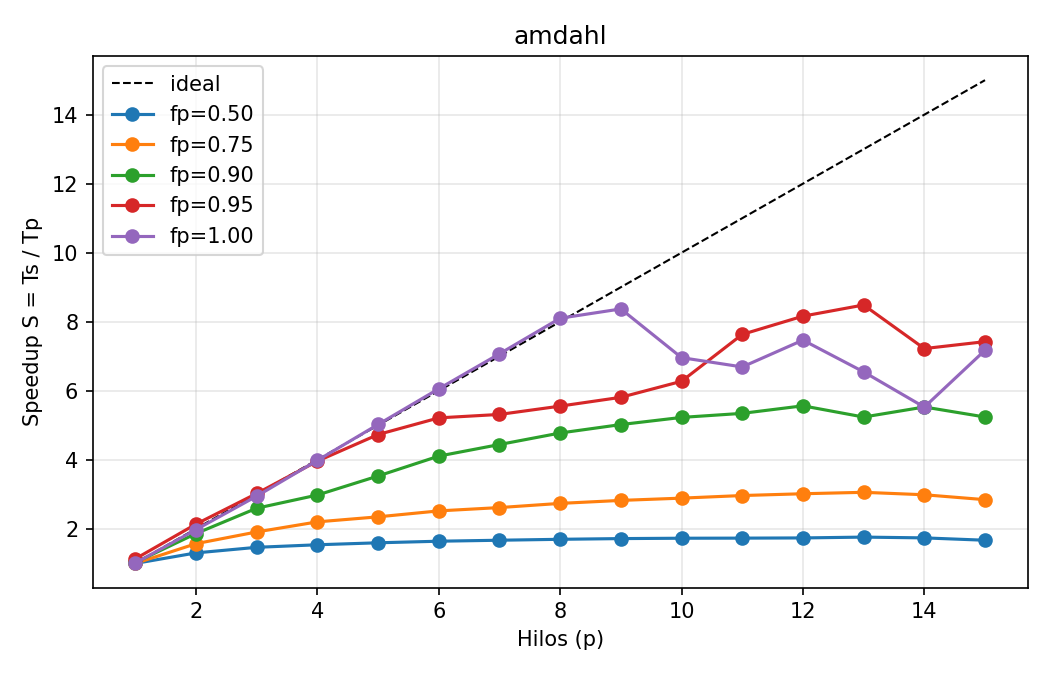

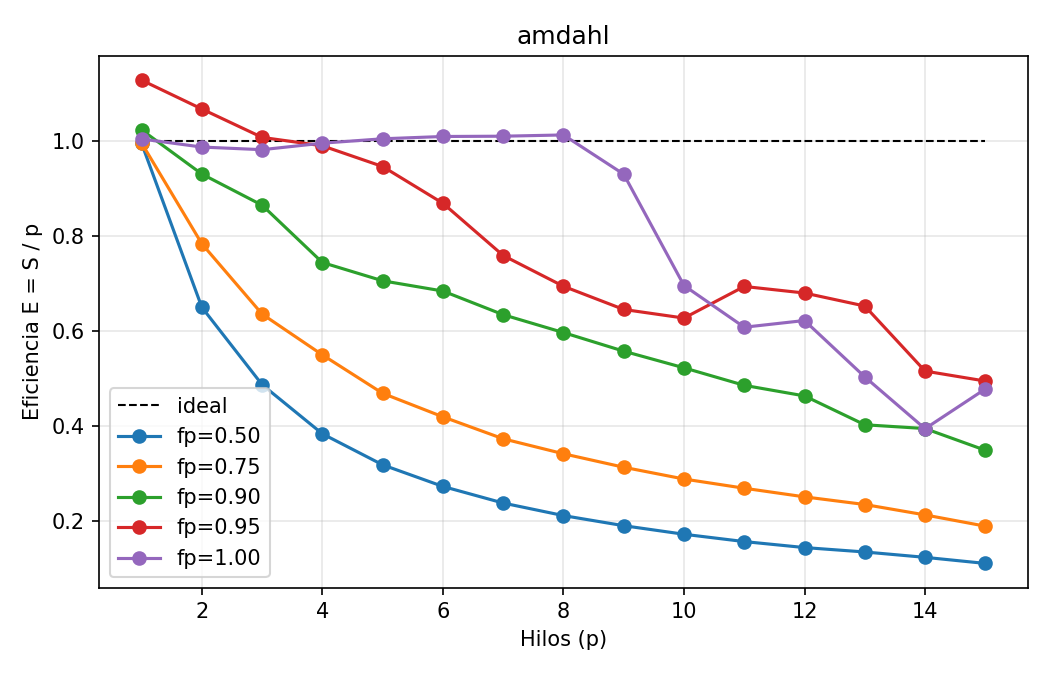

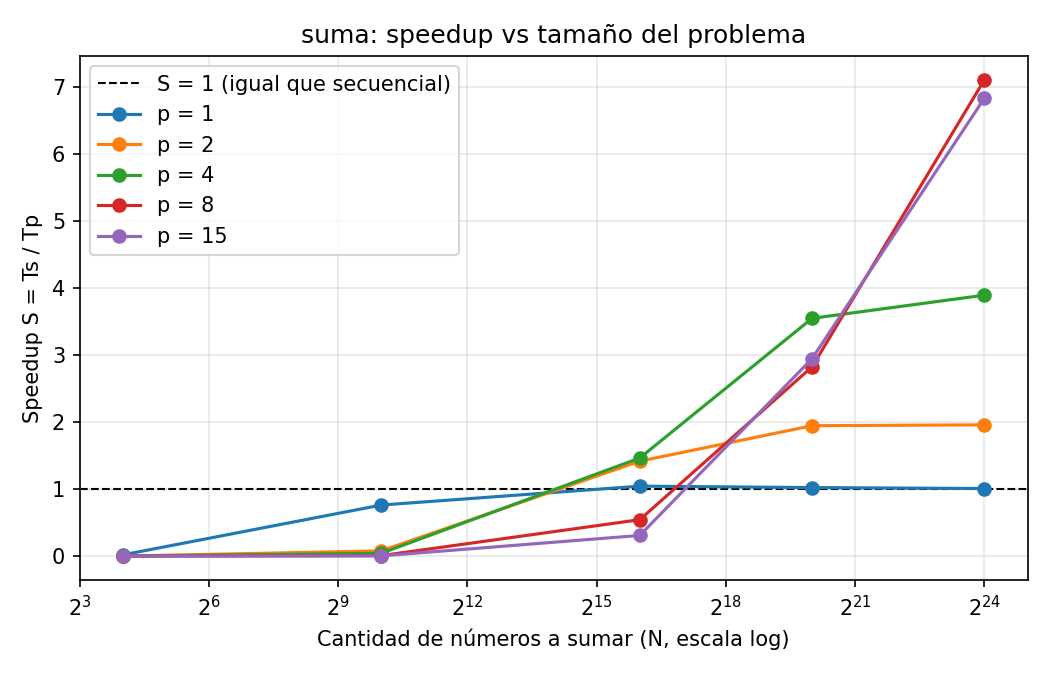

In [6]:
sh('python3 ../graficar.py amdahl_*.csv suma.csv', cwd=RES)
for png in ('amdahl_speedup.png', 'amdahl_eficiencia.png', 'suma_speedup.png'):
    display(Image(os.path.join(RES, png), width=600))

## Análisis Parte 1

In [7]:
am = pd.read_csv(os.path.join(RES, 'amdahl_con_S_E.csv'))
am['fp'] = am['param'].str.replace('fp=', '').astype(float)
PMAX = am['p'].max()

def amdahl(fp, p):
    return 1 / ((1 - fp) + fp / p)

filas = []
for fp, g in am.groupby('fp', sort=False):
    g = g.set_index('p')
    S_max = g.loc[PMAX, 'S']
    filas.append({
        'fp': fp,
        'S (p=2)': g.loc[2, 'S'], 'S (p=4)': g.loc[4, 'S'],
        f'S (p={PMAX})': S_max, f'E (p={PMAX})': g.loc[PMAX, 'E'],
        'p con F máx': int(g['F'].idxmax()),
        'p con Tp mín': int(g['t_par'].idxmin()),
        f'Amdahl S({PMAX})': amdahl(fp, PMAX),
        'fp efectivo': (1 - 1 / S_max) / (1 - 1 / PMAX),
    })
tabla1 = pd.DataFrame(filas).sort_values('fp', ascending=False)
tabla1.round(3)

,fp,S (p=2),S (p=4),S (p=15),E (p=15),p con F máx,p con Tp mín,Amdahl S(15),fp efectivo
0,1.00,1.974,3.981,7.172,0.478,8,9,15.000,0.922
4,0.95,2.134,3.959,7.422,0.495,12,13,8.824,0.927
3,0.90,1.861,2.977,5.238,0.349,8,12,6.250,0.867
2,0.75,1.567,2.199,2.842,0.189,2,13,3.333,0.694
1,0.50,1.300,1.535,1.667,0.111,1,13,1.875,0.429


In [8]:
# Cálculo a mano de S, E, C, F para dos filas (fp=0.90, p=4 y p=15)
for fp, p in ((0.90, 4), (0.90, PMAX), (1.00, PMAX)):
    r = am[(am.fp == fp) & (am.p == p)].iloc[0]
    S = r.t_seq / r.t_par; E = S / p; Cc = p * r.t_par; F = S / Cc
    print(f'fp={fp:.2f}, p={p}: Ts={r.t_seq:.6f} s, Tp={r.t_par:.6f} s')
    print(f'   S = {r.t_seq:.6f} / {r.t_par:.6f} = {S:.3f}')
    print(f'   E = {S:.3f} / {p} = {E:.3f}')
    print(f'   C = {p} * {r.t_par:.6f} = {Cc:.6f} hilo-s')
    print(f'   F = {S:.3f} / {Cc:.6f} = {F:.3f} 1/s\n')

fp=0.90, p=4: Ts=0.311342 s, Tp=0.104589 s
   S = 0.311342 / 0.104589 = 2.977
   E = 2.977 / 4 = 0.744
   C = 4 * 0.104589 = 0.418356 hilo-s
   F = 2.977 / 0.418356 = 7.116 1/s

fp=0.90, p=15: Ts=0.311342 s, Tp=0.059443 s
   S = 0.311342 / 0.059443 = 5.238
   E = 5.238 / 15 = 0.349
   C = 15 * 0.059443 = 0.891645 hilo-s
   F = 5.238 / 0.891645 = 5.874 1/s

fp=1.00, p=15: Ts=0.302829 s, Tp=0.042222 s
   S = 0.302829 / 0.042222 = 7.172
   E = 7.172 / 15 = 0.478
   C = 15 * 0.042222 = 0.633330 hilo-s
   F = 7.172 / 0.633330 = 11.325 1/s



In [9]:
# Detalle por p para fp = 1.00 y 0.75 (forma de la curva, ganancia marginal)
for fp in (1.00, 0.90, 0.75):
    g = am[am.fp == fp][['p', 't_seq', 't_par', 't_parte_seq', 'S', 'E', 'F']].copy()
    g['ΔS (hilo extra)'] = g['S'].diff()
    g['Amdahl'] = amdahl(fp, g['p'])
    display(Markdown(f'**fp = {fp:.2f}**'))
    display(g.round(4).set_index('p'))

**fp = 1.00**

,t_seq,t_par,t_parte_seq,S,E,F,ΔS (hilo extra),Amdahl
p,,,,,,,,
1,0.3028,0.3016,0.0,1.004,1.004,3.330,NaN,1.0
2,0.3028,0.1534,0.0,1.974,0.987,6.436,0.970,2.0
3,0.3028,0.1028,0.0,2.945,0.982,9.546,0.971,3.0
4,0.3028,0.0761,0.0,3.981,0.995,13.090,1.036,4.0
5,0.3028,0.0603,0.0,5.023,1.005,16.660,1.042,5.0
6,0.3028,0.0500,0.0,6.056,1.009,20.190,1.033,6.0
7,0.3028,0.0428,0.0,7.070,1.010,23.580,1.014,7.0
8,0.3028,0.0374,0.0,8.101,1.013,27.090,1.031,8.0
9,0.3028,0.0362,0.0,8.370,0.930,25.710,0.269,9.0


**fp = 0.90**

,t_seq,t_par,t_parte_seq,S,E,F,ΔS (hilo extra),Amdahl
p,,,,,,,,
1,0.3113,0.3043,0.0341,1.023,1.023,3.363,NaN,1.0000
2,0.3113,0.1673,0.0329,1.861,0.930,5.560,0.838,1.8182
3,0.3113,0.1200,0.0332,2.594,0.865,7.206,0.733,2.5000
4,0.3113,0.1046,0.0335,2.977,0.744,7.116,0.383,3.0769
5,0.3113,0.0882,0.0334,3.529,0.706,7.998,0.552,3.5714
6,0.3113,0.0758,0.0320,4.105,0.684,9.021,0.576,4.0000
7,0.3113,0.0701,0.0326,4.441,0.634,9.049,0.336,4.3750
8,0.3113,0.0652,0.0323,4.775,0.597,9.152,0.334,4.7059
9,0.3113,0.0620,0.0317,5.019,0.558,8.990,0.244,5.0000


**fp = 0.75**

,t_seq,t_par,t_parte_seq,S,E,F,ΔS (hilo extra),Amdahl
p,,,,,,,,
1,0.295,0.2963,0.0814,0.996,0.996,3.360,NaN,1.0000
2,0.295,0.1882,0.0797,1.567,0.784,4.162,0.571,1.6000
3,0.295,0.1547,0.0810,1.907,0.636,4.110,0.340,2.0000
4,0.295,0.1341,0.0792,2.199,0.550,4.099,0.292,2.2857
5,0.295,0.1258,0.0805,2.345,0.469,3.728,0.146,2.5000
6,0.295,0.1172,0.0803,2.517,0.419,3.579,0.172,2.6667
7,0.295,0.1129,0.0801,2.613,0.373,3.307,0.096,2.8000
8,0.295,0.1079,0.0792,2.735,0.342,3.169,0.122,2.9091
9,0.295,0.1046,0.0792,2.821,0.313,2.997,0.086,3.0000


## Análisis Parte 2

In [10]:
# 2a — Ts honesto: t_seq vs t_par(p=1) con fp = 1.00
r = am[(am.fp == 1.00) & (am.p == 1)].iloc[0]
print(f't_seq        = {r.t_seq:.6f} s')
print(f't_par (p=1)  = {r.t_par:.6f} s')
print(f'diferencia   = {(r.t_par - r.t_seq) / r.t_seq * 100:+.2f} % (positivo = OpenMP 1 hilo más lento)')

t_seq        = 0.302829 s
t_par (p=1)  = 0.301577 s
diferencia   = -0.41 % (positivo = OpenMP 1 hilo más lento)


In [11]:
su = pd.read_csv(os.path.join(RES, 'suma_con_S_E.csv'))
su['Ts (ns)'] = su['t_seq'] * 1e9
su['Tp (ns)'] = su['t_par'] * 1e9
su['GB/s par'] = su['N'] * 8 / su['t_par'] / 1e9
su['GB/s seq'] = su['N'] * 8 / su['t_seq'] / 1e9
display(su.pivot(index='N', columns='p', values='S').round(3))
display(su.pivot(index='N', columns='p', values='Tp (ns)').round(1))
display(su.groupby('N')[['Ts (ns)', 'GB/s seq']].first().round(2))
display(su.pivot(index='N', columns='p', values='GB/s par').round(1))

p,1,2,4,8,15
N,,,,,
16,0.019,0.000,0.000,0.000,0.000
1024,0.761,0.079,0.042,0.007,0.004
65536,1.043,1.416,1.463,0.543,0.308
1048576,1.022,1.945,3.546,2.823,2.945
16777216,1.008,1.957,3.891,7.101,6.828


p,1,2,4,8,15
N,,,,,
16,54.0,4571.0,9608.0,55291.0,108128.0
1024,570.0,5522.0,10220.0,58068.0,108760.0
65536,32782.0,24152.0,23372.0,62964.0,110939.0
1048576,550508.0,289364.0,158701.0,199318.0,191085.0
16777216,8713007.0,4485687.0,2256632.0,1236359.0,1285950.0


,Ts (ns),GB/s seq
N,,
16,1.0,128.00
1024,434.0,18.88
65536,34196.0,15.33
1048576,562683.0,14.91
16777216,8780003.0,15.29


p,1,2,4,8,15
N,,,,,
16,2.4,0.0,0.0,0.0,0.0
1024,14.4,1.5,0.8,0.1,0.1
65536,16.0,21.7,22.4,8.3,4.7
1048576,15.2,29.0,52.9,42.1,43.9
16777216,15.4,29.9,59.5,108.6,104.4


In [12]:
# Dónde cruza S = 1: interpolación en log2(N) para p = pmax
import numpy as np
for p in sorted(su.p.unique()):
    g = su[su.p == p].sort_values('N')
    ln, s = np.log2(g.N.values), g.S.values
    cruce = None
    for i in range(len(s) - 1):
        if s[i] < 1 <= s[i + 1]:
            t = (1 - s[i]) / (s[i + 1] - s[i])
            cruce = 2 ** (ln[i] + t * (ln[i + 1] - ln[i]))
            break
    print(f'p={p:2d}: S cruza 1 cerca de N ≈ {cruce:,.0f}' if cruce else f'p={p:2d}: no cruza en el rango')

p= 1: S cruza 1 cerca de N ≈ 34,759
p= 2: S cruza 1 cerca de N ≈ 17,968
p= 4: S cruza 1 cerca de N ≈ 16,904
p= 8: S cruza 1 cerca de N ≈ 114,244
p=15: S cruza 1 cerca de N ≈ 135,664
